<a href="https://colab.research.google.com/github/ofelia2510126-droid/analisis_exploratorio/blob/main/3_ejercicios_pandas_delitos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis exploratorio de incidencia delictiva en México

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [10]:
df = pd.read_csv('datos_delitos.csv', encoding='latin-1')

#### Ejercicio 1: Elige 3 estados de la república y grafica una serie de tiempo de la frecuencia abosluta de homicidios dolosos de enero 2015 a julio 2019 en estas tres entidades

/tmp/ipykernel_814/89324472.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_f = df_h[df['Entidad'].isin(estados)]


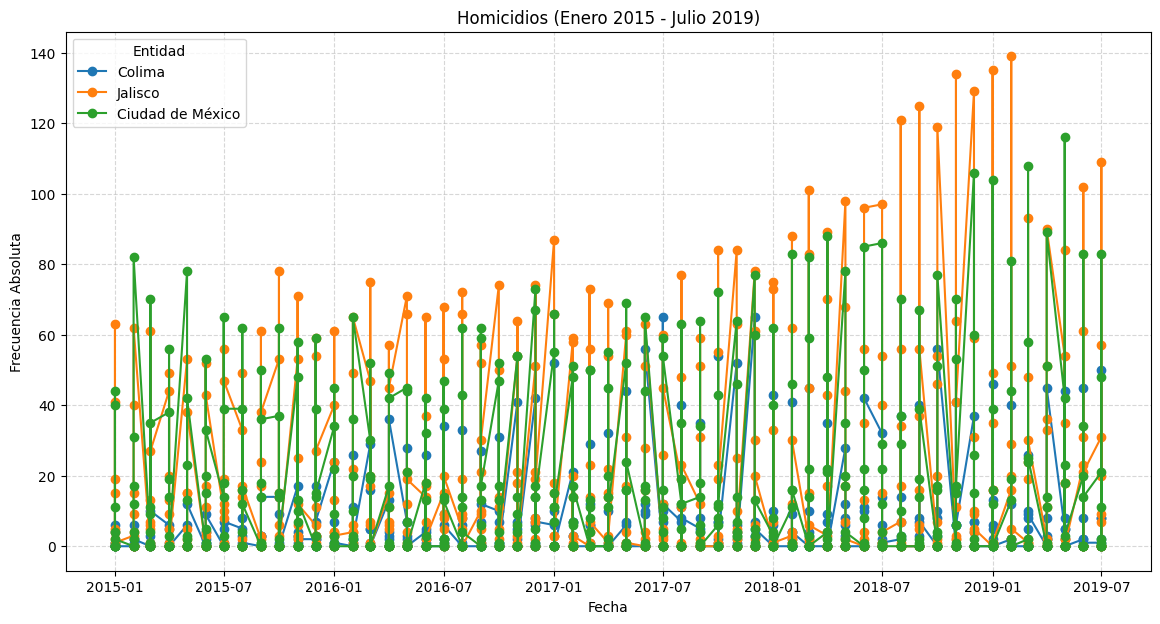

In [18]:
# 1. Filtrar estados y tipo de delito
estados = ['Colima', 'Jalisco', 'Ciudad de México']
df_h = df[df['Tipo de delito'] == 'Homicidio']
df_f = df_h[df['Entidad'].isin(estados)]

# 2. Pasar meses a filas y crear fecha datetime
meses = {'Enero':1, 'Febrero':2, 'Marzo':3, 'Abril':4, 'Mayo':5, 'Junio':6, 'Julio':7,
         'Agosto':8, 'Septiembre':9, 'Octubre':10, 'Noviembre':11, 'Diciembre':12}

df_melt = df_f.melt(id_vars=['Año', 'Entidad'], value_vars=list(meses.keys()), var_name='Mes_Str', value_name='Frecuencia')
df_melt['Mes'] = df_melt['Mes_Str'].map(meses)
df_melt['fecha'] = pd.to_datetime(df_melt['Año'].astype(str) + '-' + df_melt['Mes'].astype(str) + '-01')

# 3. Filtrar el rango exacto (Ene 2015 a Jul 2019)
df_final = df_melt[(df_melt['fecha'] >= '2015-01-01') & (df_melt['fecha'] <= '2019-07-31')]

# 4. Graficar
plt.figure(figsize=(14, 7))
for est in estados:
    d = df_final[df_final['Entidad'] == est].sort_values('fecha')
    plt.plot(d['fecha'], d['Frecuencia'], label=est, marker='o')

plt.title('Homicidios (Enero 2015 - Julio 2019)')
plt.xlabel('Fecha')
plt.ylabel('Frecuencia Absoluta')
plt.legend(title='Entidad')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#### Ejercicio 2: Contetas las siguientes  preguntas:
1. ¿Cuántos homicidios dolosos hubo en Colima en el 2018?
2. ¿Cuantos robos de vehículo automotor ha habido en el 2019?
3. Obten la suma de homicidos dolosos y feminidios en toda la República Mexicana en cada año.
4. ¿En qué mes y en qué municipio ha ocurrido el mayor número de feminicidios?
5. ¿En qué año y en qué estado ha ocurrido el mayor número de feminicidios?

In [21]:
df_colima_2018 = df_melt[(df_melt['Entidad'] == 'Colima') & (df_melt['Año'] == 2018)]
total_colima_2018 = df_colima_2018['Frecuencia'].sum()
print(f"Total de homicidios en Colima en 2018: {total_colima_2018}")

Total de homicidios en Colima en 2018: 726.0


In [22]:
# Filtrar por el tipo de delito de robo de vehículo (ajusta el texto exacto según aparezca en tu columna 'Tipo de delito')
df_robo = df[df['Tipo de delito'].str.contains('Robo de vehículo', case=False, na=False)]

# Filtrar para el año 2019 y sumar todos los meses
meses = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio', 'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']
df_2019 = df_robo[df_robo['Año'] == 2019]

total_robos_2019 = df_2019[meses].sum().sum()
print(f"Total de robos de vehículo automotor en 2019: {total_robos_2019}")

Total de robos de vehículo automotor en 2019: 0.0


In [23]:
# 1. Filtrar los dos tipos de delito de interés
delitos_interes = ['Homicidio', 'Feminicidio'] # Ajusta el texto exacto si tu dataset los nombra distinto (ej. 'Homicidio doloso')
df_delitos = df[df['Tipo de delito'].isin(delitos_interes)]

# 2. Lista de meses que forman las columnas de conteo
meses = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio', 'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']

# 3. Agrupar por año y sumar todos los meses de esos delitos
df_anual = df_delitos.groupby('Año')[meses].sum().sum(axis=1).reset_index(name='Total_Delitos')

print(df_anual)

    Año  Total_Delitos
0  2015        31744.0
1  2016        36018.0
2  2017        42068.0
3  2018        45385.0
4  2019        45822.0
5  2020        44223.0
6  2021        44960.0
7  2022        43845.0
8  2023        42846.0
9  2024        22307.0


In [26]:
# Detectar columnas disponibles para agrupar
id_cols = ['Año', 'Entidad']
if 'Municipio' in df.columns:
    id_cols.append('Municipio')

# Filtrar, transformar y ordenar el valor máximo
df_m = df[df['Tipo de delito'].str.contains('Feminicidio', case=False, na=False)].melt(
    id_vars=id_cols,
    value_vars=['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio', 'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre'],
    var_name='Mes',
    value_name='Total'
)

df_m.sort_values('Total', ascending=False).head(1)

,Año,Entidad,Mes,Total
4342,2018,Veracruz de Ignacio de la Llave,Abril,16.0


In [27]:
# Agrupar por Año y Entidad sumando todos los meses del delito de Feminicidio
df_fem = df[df['Tipo de delito'].str.contains('Feminicidio', case=False, na=False)]
meses = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio', 'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']

df_grouped = df_fem.groupby(['Año', 'Entidad'])[meses].sum().sum(axis=1).reset_index(name='Total_Feminicidios')

# Mostrar el registro con la cifra más alta a nivel estatal e histórico en el archivo
print(df_grouped.sort_values(by='Total_Feminicidios', ascending=False).head(1))

      Año Entidad  Total_Feminicidios
176  2020  México               151.0


#### Ejercicio 3: Haz una gráfica de pastel de tipos de delito. Deberás crear una gráfica para cada año. Utilzia la función subplots de matplotlib

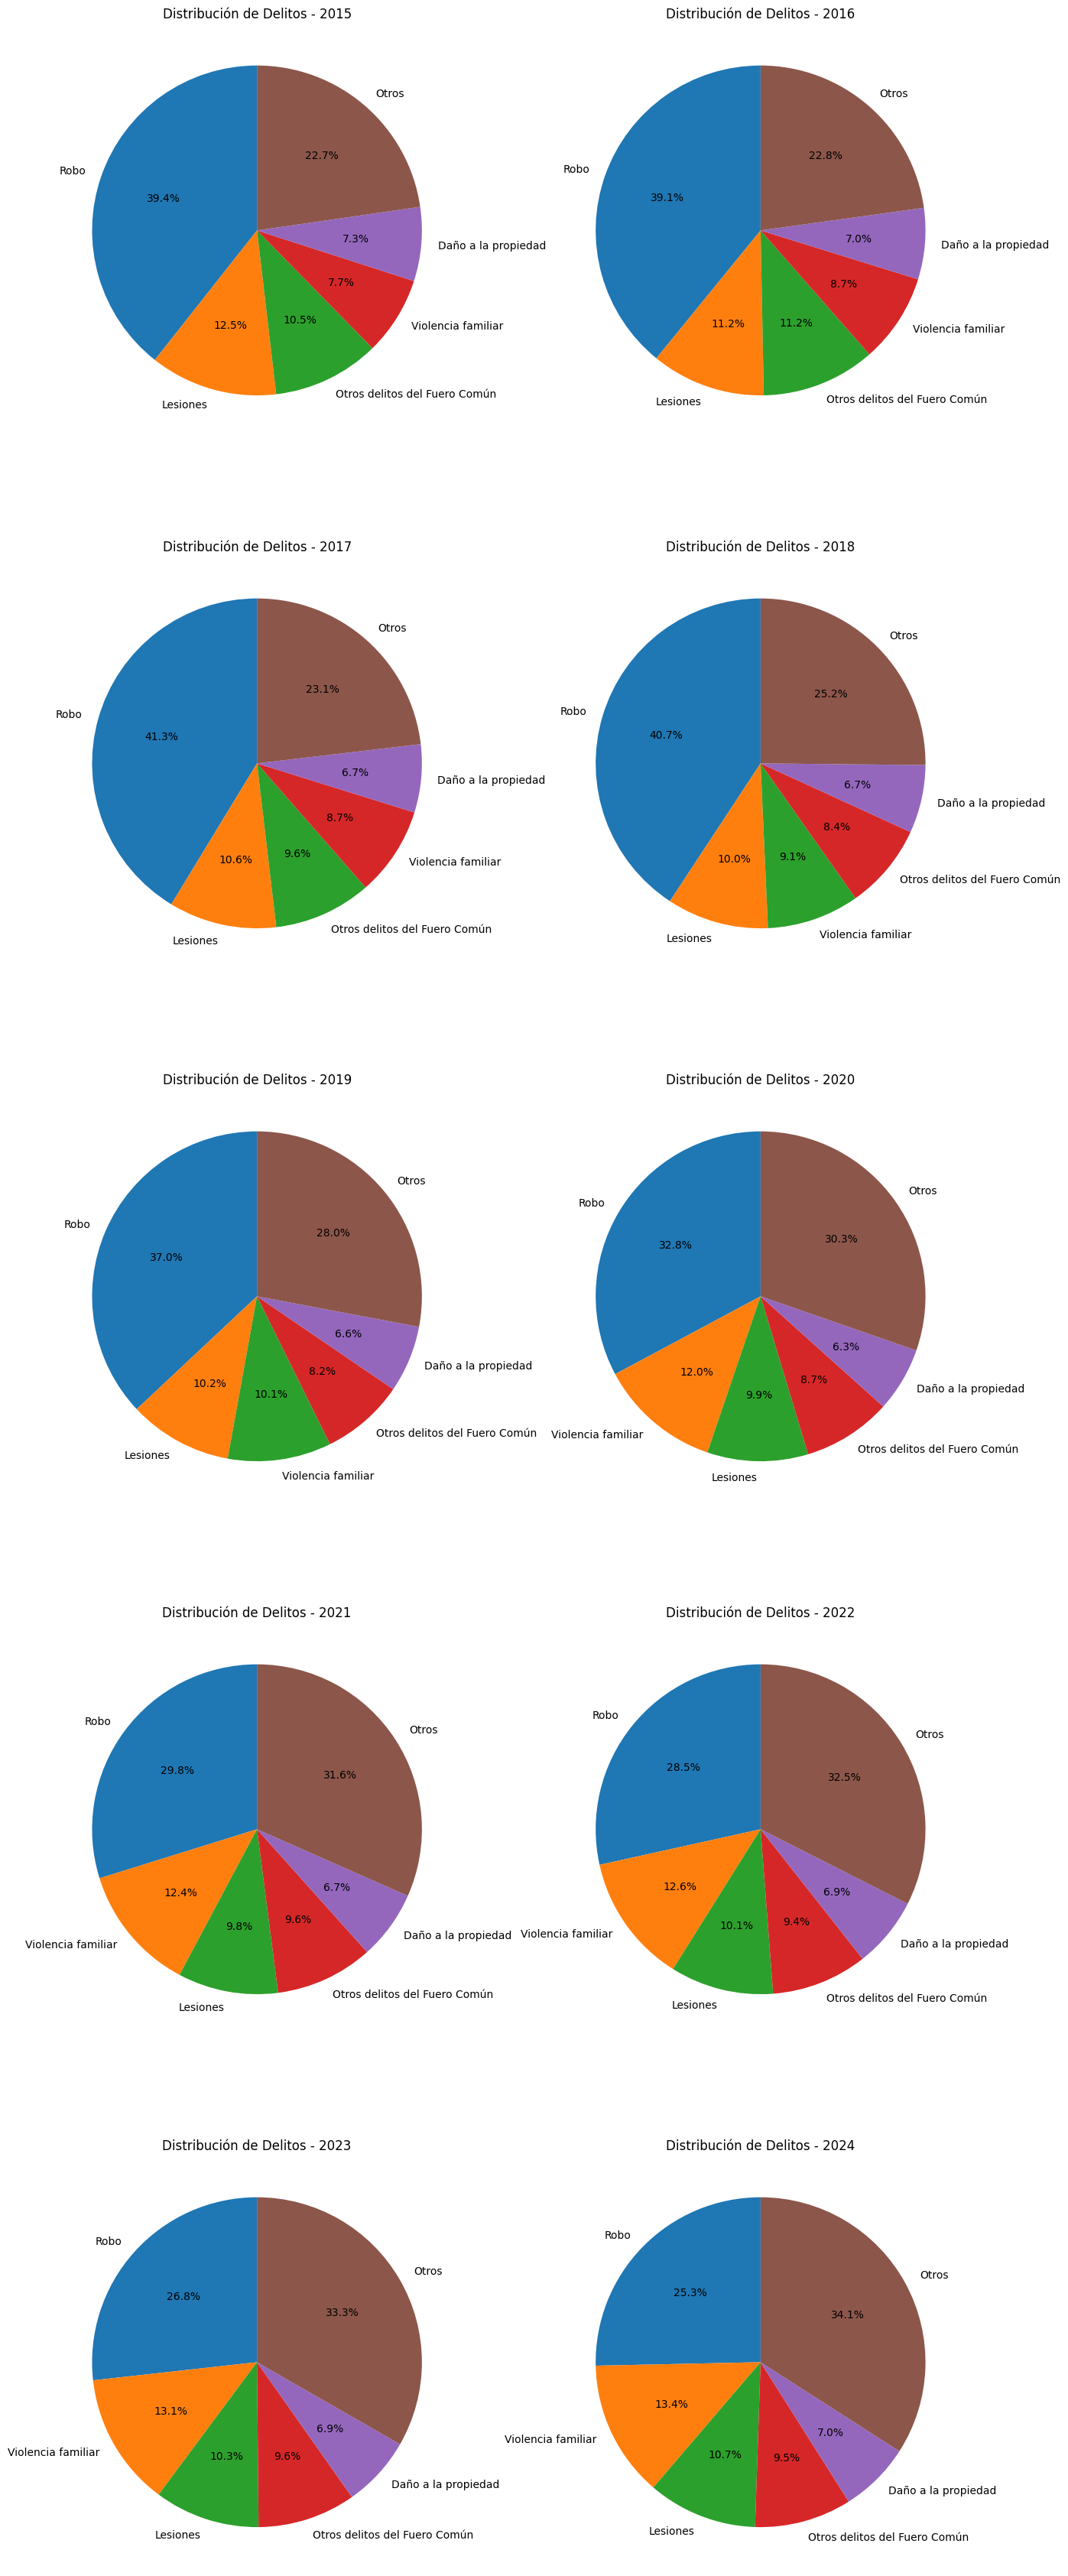

In [30]:
import matplotlib.pyplot as plt

# 1. Agrupar por Año y Tipo de delito sumando todos los meses
meses = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio', 'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']
df_delitos = df.groupby(['Año', 'Tipo de delito'])[meses].sum().sum(axis=1).reset_index(name='Total')

anios = sorted(df_delitos['Año'].unique())
n = len(anios)

# 2. Configurar la cuadrícula de subplots
fig, axes = plt.subplots(nrows=(n // 2) + (n % 2), ncols=2, figsize=(14, 7 * ((n // 2) + (n % 2))))
axes = axes.flatten()

# 3. Generar un gráfico de pastel por cada año agrupando los menores en "Otros"
for i, anio in enumerate(anios):
    df_anio = df_delitos[df_delitos['Año'] == anio].sort_values('Total', ascending=False)

    # Tomar los 5 delitos principales y agrupar el resto en "Otros"
    top_n = 5
    if len(df_anio) > top_n:
        df_top = df_anio.head(top_n).copy()
        otros_total = df_anio.iloc[top_n:]['Total'].sum()

        # Añadir la fila "Otros"
        otros_row = pd.DataFrame({'Año': [anio], 'Tipo de delito': ['Otros'], 'Total': [otros_total]})
        df_plot = pd.concat([df_top, otros_row], ignore_index=True)
    else:
        df_plot = df_anio

    axes[i].pie(df_plot['Total'], labels=df_plot['Tipo de delito'], autopct='%1.1f%%', startangle=90)
    axes[i].set_title(f'Distribución de Delitos - {anio}')

# Ocultar subplots sobrantes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

---
#### Calcula la tasa por 100,000 habitantes
##### Tasa por 100,000 habitantes
Mostrar el total de delitos en una entidad no nos sirve de mucho. Es mucho más útil calcular la tasa de incidencia delictiva por cada 100,000 habitantes

$$
tasa = \frac{delitos\space totales}{población} \times 100,000
$$

Esta tasa la podemos anualizar multiplicándola por un factor de 12
$$
tasa\space anualizada = tasa \times 12
$$

Población por entidad federativa según [la encuesta intercensal 2015](https://www.inegi.org.mx/programas/intercensal/2015/)

No tienes que descargar nada. Ya están los datos en la carpeta data

In [45]:
# 1. Cargar correctamente el archivo indicando que el separador es el punto y coma (;)
pobs = pd.read_csv('data/poblacion_entidades_2015.csv', encoding='iso-8859-1', sep=';')
pobs.columns = pobs.columns.str.strip()

# 2. Calcular el total de delitos por entidad en el año 2015
meses = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio', 'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']
df_2015 = df[df['Año'] == 2015]
delitos_2015 = df_2015.groupby('Entidad')[meses].sum().sum(axis=1).reset_index(name='delitos_totales')

# 3. Unir la tabla de delitos con la de población usando los nombres exactos de las columnas
df_tasa = pd.merge(delitos_2015, pobs, left_on='Entidad', right_on='Entidad')

# 4. Calcular la tasa por cada 100,000 habitantes
df_tasa['tasa'] = (df_tasa['delitos_totales'] / df_tasa['Poblacion']) * 100000

# 5. Mostrar el resultado ordenado de mayor a menor tasa
df_tasa[['Entidad', 'delitos_totales', 'Poblacion', 'tasa']].sort_values(by='tasa', ascending=False).head(10)

,Entidad,delitos_totales,Poblacion,tasa
6,Ciudad de México,169701.0,711235.0,23860.046258
1,Baja California,119944.0,3315766.0,3617.384339
2,Baja California Sur,21415.0,712029.0,3007.602218
15,Morelos,49245.0,1903811.0,2586.653822
26,Tabasco,57452.0,2395272.0,2398.558494
22,Quintana Roo,32496.0,1501562.0,2164.146402
5,Chihuahua,61280.0,2954915.0,2073.832919
16,México,323525.0,16187608.0,1998.596704
0,Aguascalientes,23212.0,1312544.0,1768.474047
9,Durango,29088.0,1754754.0,1657.668254


In [52]:
import pandas as pd

# 1. Cargar población con el separador correcto y limpiar espacios
pobs = pd.read_csv('data/poblacion_entidades_2015.csv', encoding='iso-8859-1', sep=';')
pobs.columns = pobs.columns.str.strip()
pobs = pobs[['Cve_Entidad', 'Entidad', 'Poblacion']].dropna(subset=['Poblacion'])
pobs['Cve_Entidad'] = pobs['Cve_Entidad'].astype(int)

# 2. Transformar el DataFrame de delitos de formato ancho a formato largo (meses a filas)
meses = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio',
         'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']

df_melted = df.melt(
    id_vars=['Año', 'Clave_Ent', 'Entidad', 'Bien jurídico afectado', 'Tipo de delito', 'Subtipo de delito', 'Modalidad'],
    value_vars=meses,
    var_name='nombre_mes',
    value_name='frecuencia'
)

# 3. Asegurar tipos de datos para el cruce
df_melted['Clave_Ent'] = df_melted['Clave_Ent'].astype(int)

# 4. Unir con la tabla de población usando las claves numéricas
df_tasas = pd.merge(df_melted, pobs, left_on='Clave_Ent', right_on='Cve_Entidad')

# 5. Calcular la tasa mensual y la tasa anualizada por cada 100,000 habitantes
df_tasas['tasa'] = (df_tasas['frecuencia'] / df_tasas['Poblacion']) * 100000
df_tasas['tasa_anualizada'] = df_tasas['tasa'] * 12

# Mostrar resultado exitoso
print("¡Transformación, merge y cálculos exitosos!")
display(df_tasas[['Entidad_x', 'Tipo de delito', 'nombre_mes', 'frecuencia', 'Poblacion', 'tasa_anualizada']].head())

¡Transformación, merge y cálculos exitosos!


,Entidad_x,Tipo de delito,nombre_mes,frecuencia,Poblacion,tasa_anualizada
0,Aguascalientes,Homicidio,Enero,3.0,1312544.0,2.742765
1,Aguascalientes,Homicidio,Enero,1.0,1312544.0,0.914255
2,Aguascalientes,Homicidio,Enero,0.0,1312544.0,0.000000
3,Aguascalientes,Homicidio,Enero,2.0,1312544.0,1.828510
4,Aguascalientes,Homicidio,Enero,0.0,1312544.0,0.000000


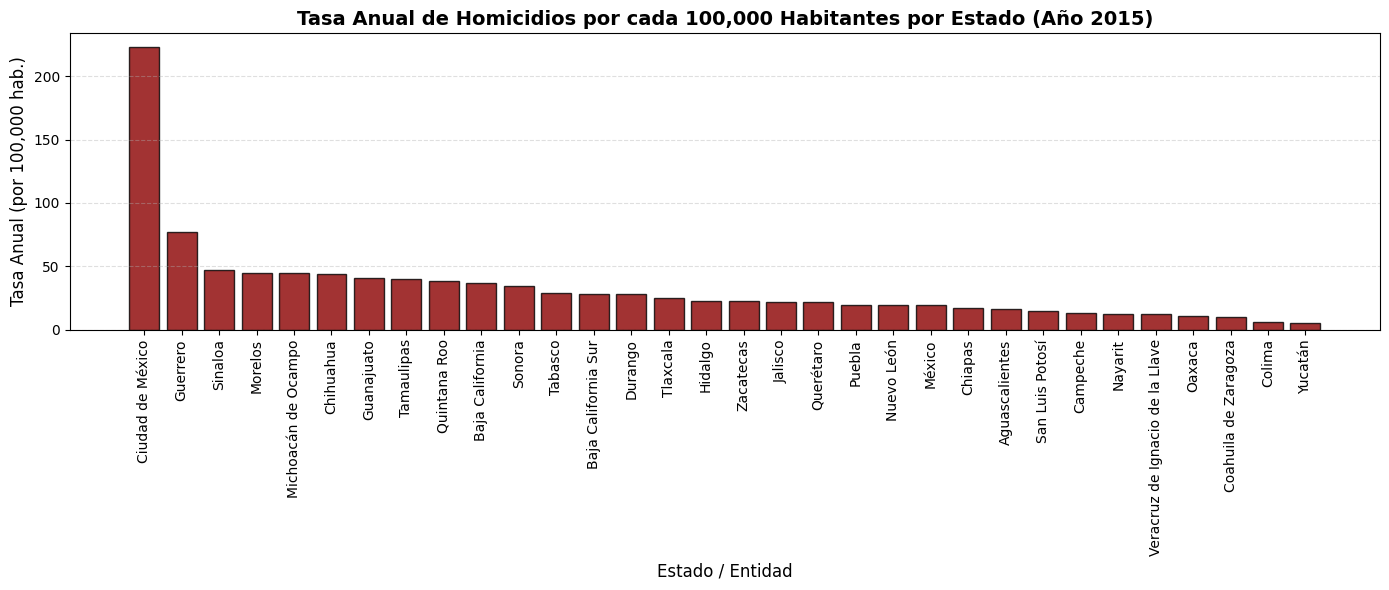

Top 5 de estados con mayor tasa anual de Homicidios en 2015:


,Entidad_x,tasa_anual
6,Ciudad de México,222.851800
11,Guerrero,77.011228
24,Sinaloa,47.331358
15,Morelos,44.699815
14,Michoacán de Ocampo,44.519858


In [55]:
# 1. Filtramos por Homicidio usando el nombre exacto
homicidios_tasas = df_tasas[df_tasas['Tipo de delito'] == 'Homicidio']

# 2. Agrupamos usando 'Entidad_x' que generó el merge
homicidios_anual = homicidios_tasas.groupby(['Año', 'Entidad_x', 'Poblacion'])[['frecuencia']].sum().reset_index()
homicidios_anual['tasa_anual'] = (homicidios_anual['frecuencia'] / homicidios_anual['Poblacion']) * 100000

# 3. Filtrar y ordenar los estados por tasa en el año 2015 de mayor a menor
homicidios_2015 = homicidios_anual[homicidios_anual['Año'] == 2015].sort_values(by='tasa_anual', ascending=False)

# 4. Graficar
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plt.bar(homicidios_2015['Entidad_x'], homicidios_2015['tasa_anual'], color='darkred', edgecolor='black', alpha=0.8)
plt.title('Tasa Anual de Homicidios por cada 100,000 Habitantes por Estado (Año 2015)', fontsize=14, fontweight='bold')
plt.xlabel('Estado / Entidad', fontsize=12)
plt.ylabel('Tasa Anual (por 100,000 hab.)', fontsize=12)
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# 5. Imprimir el Top 5 de estados con mayor tasa en 2015
print("Top 5 de estados con mayor tasa anual de Homicidios en 2015:")
display(homicidios_2015[['Entidad_x', 'tasa_anual']].head(5))